# Détection de rééchantillonnage sur RAISE — pipeline complet et étude statistique


Ce notebook montre, sur **une vraie photo RAISE**, chaque étape de notre pipeline, puis analyse statistiquement les résultats obtenus sur toute la dataset préparée (`results/detection_png_rt.csv`).

**Plan**
1. La dataset préparée
2. Préparation d'une image : TIFF → luminance → ↓×2 → rééchantillonnage ×q → recadrage 600×600
3. Extraction du résidu (rank transform)
4. Spectre et corrélations de patches
5. Votes, NFA, validation croisée et décision
6. Étude statistique des résultats
7. Synthèse

In [1]:
import os, sys
# le notebook est dans code_ima/notebooks : on se place a la racine du projet
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

from src.image_io import read_image, rgb_to_luminance, load_gray
from src.dataset import downsample2, center_crop, resample_and_crop, expected_distances, crop_size_for, KERNELS, FACTORS, OUT_SIZE
from src.residual import rank_transform_2d
from src.spectral import patch_correlations_2d
from src.acontrario import count_votes, compute_nfa, cross_validate
from src.detector import detect

DATA = "data/raise_prepared"
RESULTS = "results/detection_png_rt.csv"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("racine du projet :", ROOT)

racine du projet : c:\Users\User\Downloads\projet ima01\code_ima


## 1. La dataset préparée

`scripts/prepare_raise.py` a produit, pour chaque photo RAISE, **1 originale** (q = 1) et **40 versions rééchantillonnées** (4 noyaux × 10 facteurs), chacune en PNG, JPEG 95 et JPEG 90. Toutes font 600×600. Le fichier `index.csv` décrit chaque image de test.

In [2]:
idx = pd.read_csv(os.path.join(DATA, "index.csv"))
print(f"{idx['id'].nunique()} photos, {len(idx)} images de test")
display(idx.groupby(["label", "format"]).size().unstack())
display(idx.head(3))

20 photos, 2460 images de test


format,jpeg90,jpeg95,png
label,,,
original,20,20,20
resampled,800,800,800


,id,device,label,kernel,q,format,path,size,d1,d2,source
0,r000da54ft,Nikon D90,original,none,1.0,png,original\png\r000da54ft.png,600,NaN,NaN,data/raise/tiff\r000da54ft.TIF
1,r000da54ft,Nikon D90,original,none,1.0,jpeg95,original\jpeg95\r000da54ft.jpg,600,NaN,NaN,data/raise/tiff\r000da54ft.TIF
2,r000da54ft,Nikon D90,original,none,1.0,jpeg90,original\jpeg90\r000da54ft.jpg,600,NaN,NaN,data/raise/tiff\r000da54ft.TIF


## 2. Préparation d'une image, étape par étape

On suit **une photo** et **un cas de test** : rééchantillonnage bicubique ×1,2. On peut changer `PHOTO`, `Q` et `KERNEL`.

In [3]:
PHOTO = idx["id"].iloc[0]
Q, KERNEL = 1.2, "cubic"
src = idx.loc[idx["id"] == PHOTO, "source"].iloc[0].replace("\\", "/")

rgb = read_image(src)              # (H, W, 3) float sur [0,255]
gray = rgb_to_luminance(rgb)       # (H, W)    Y = 0.299R + 0.587G + 0.114B
half = downsample2(gray)           # moyenne 2x2 : efface le dematricage
orig = center_crop(half, OUT_SIZE)                 # image ORIGINALE de test
res = resample_and_crop(half, Q, KERNEL)           # image REECHANTILLONNEE de test
s_in, s_out = crop_size_for(Q)
d_exp = expected_distances(Q)

for name, a in [("TIFF RGB", rgb), ("luminance", gray), ("apres x1/2", half), ("originale 600x600", orig), (f"reech. x{Q} 600x600", res)]:
    print(f"{name:22s} forme {str(a.shape):18s} min {a.min():6.1f}  max {a.max():6.1f}")
print(f"\nreechantillonnage : carre central {s_in}x{s_in} -> {s_out}x{s_out} (rapport exact {s_out/s_in}), puis centre 600x600")
print(f"distances theoriques du pic : d = +-600/q mod 600 = {[round(d, 2) for d in d_exp]}")

TIFF RGB               forme (2848, 4288, 3)    min    0.0  max  255.0
luminance              forme (2848, 4288)       min    0.0  max  255.0
apres x1/2             forme (1424, 2144)       min    3.0  max  255.0
originale 600x600      forme (600, 600)         min    5.5  max  253.3
reech. x1.2 600x600    forme (600, 600)         min    9.5  max  253.3

reechantillonnage : carre central 520x520 -> 624x624 (rapport exact 1.2), puis centre 600x600
distances theoriques du pic : d = +-600/q mod 600 = [100.0, 500.0]


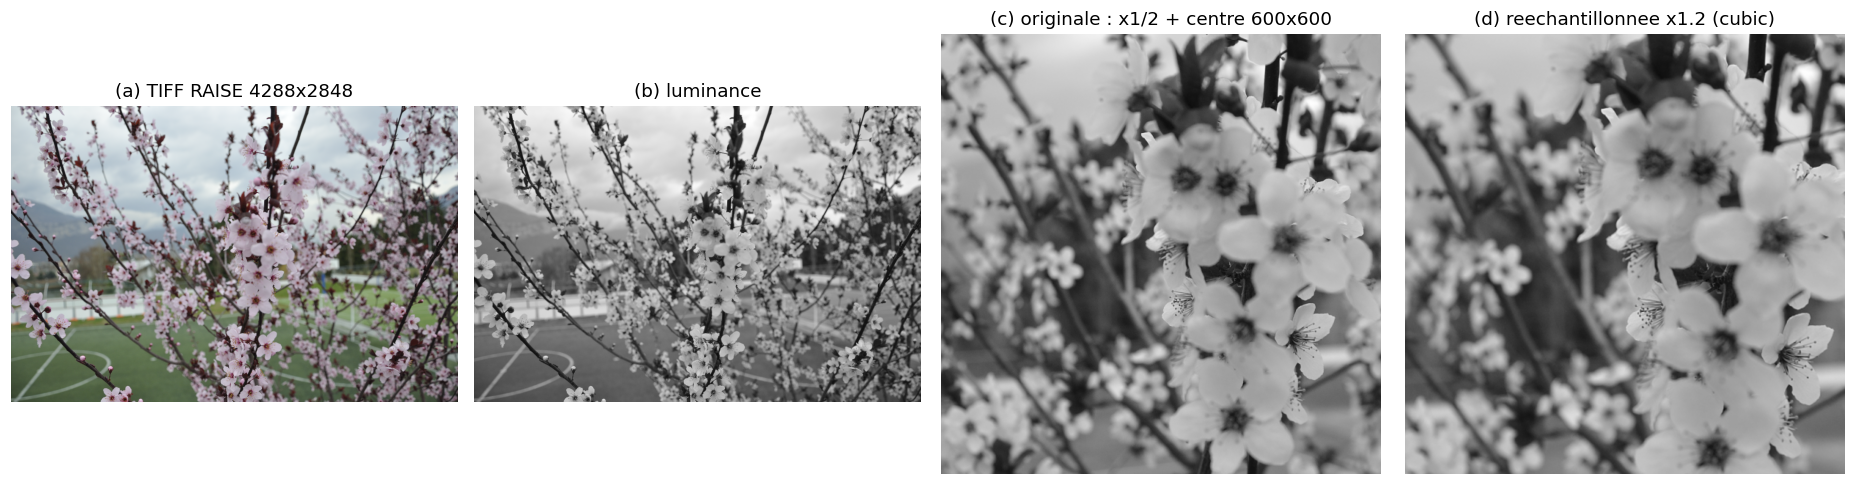

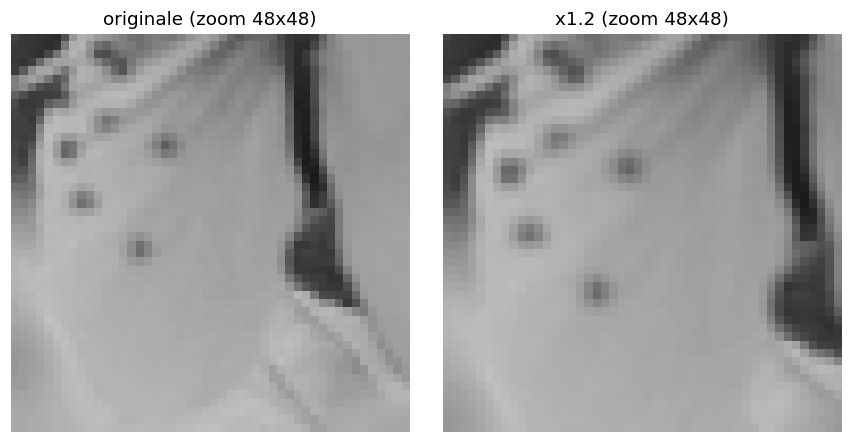

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.3))
ax[0].imshow(rgb.astype(np.uint8)[::4, ::4]); ax[0].set_title(f"(a) TIFF RAISE {rgb.shape[1]}x{rgb.shape[0]}")
ax[1].imshow(gray[::4, ::4], cmap="gray", vmin=0, vmax=255); ax[1].set_title("(b) luminance")
ax[2].imshow(orig, cmap="gray", vmin=0, vmax=255); ax[2].set_title("(c) originale : x1/2 + centre 600x600")
ax[3].imshow(res, cmap="gray", vmin=0, vmax=255); ax[3].set_title(f"(d) reechantillonnee x{Q} ({KERNEL})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# zoom : l'interpolation lisse les details
z = 48
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(orig[300:300+z, 300:300+z], cmap="gray", vmin=0, vmax=255, interpolation="nearest"); ax[0].set_title("originale (zoom 48x48)")
ax[1].imshow(res[300:300+z, 300:300+z], cmap="gray", vmin=0, vmax=255, interpolation="nearest"); ax[1].set_title(f"x{Q} (zoom 48x48)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Vérification :** l'image recalculée ici doit être identique au PNG enregistré par `prepare_raise.py` (à l'arrondi 8 bits près, soit au plus 0,5).

In [5]:
p = os.path.join(DATA, "resampled", KERNEL, f"q{Q:.1f}", "png", f"{PHOTO}.png")
print("ecart max avec le PNG enregistre :", np.abs(load_gray(p) - res).max())

ecart max avec le PNG enregistre : 0.5


## 3. Extraction du résidu : rank transform 7×7

$R(x) = \#\{x' \in \mathcal{N}(x) : I(x') < I(x)\}$ (éq. 15 du papier). Seul l'ordre local est gardé : le contenu de la scène (intensités, dégradés) disparaît, et le résidu ressemble à un bruit, ce qui rend l'hypothèse $H_0$ réaliste.

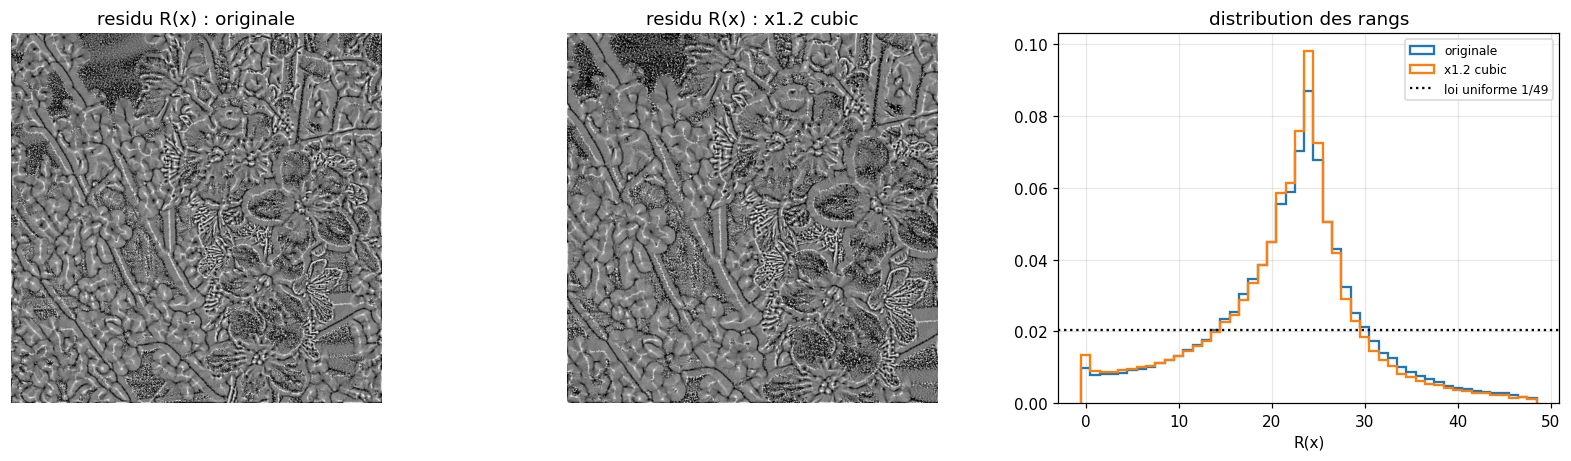

In [6]:
imgs = {"originale": load_gray(os.path.join(DATA, "original", "png", f"{PHOTO}.png")), f"x{Q} {KERNEL}": load_gray(p)}
Rs = {k: rank_transform_2d(v, s=3) for k, v in imgs.items()}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (k, R) in zip(ax[:2], Rs.items()):
    a.imshow(R, cmap="gray", vmin=0, vmax=48); a.set_title(f"residu R(x) : {k}"); a.axis("off")
for k, R in Rs.items():
    ax[2].hist(R.ravel(), bins=49, range=(-0.5, 48.5), histtype="step", lw=1.5, density=True, label=k)
ax[2].axhline(1/49, color="k", ls=":", label="loi uniforme 1/49")
ax[2].set_xlabel("R(x)"); ax[2].set_title("distribution des rangs"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Spectre du résidu et corrélations de patches

Le rééchantillonnage **replie le spectre** : des patches séparés de $d = \pm M \bmod N$ composantes deviennent corrélés. Ici $N = 600$ et $M = 600/q$. On mesure le PCC complexe entre chaque patch $P_i$ (taille $60\times60$) et le patch situé $d$ composantes plus loin, pour toutes les distances $d$.

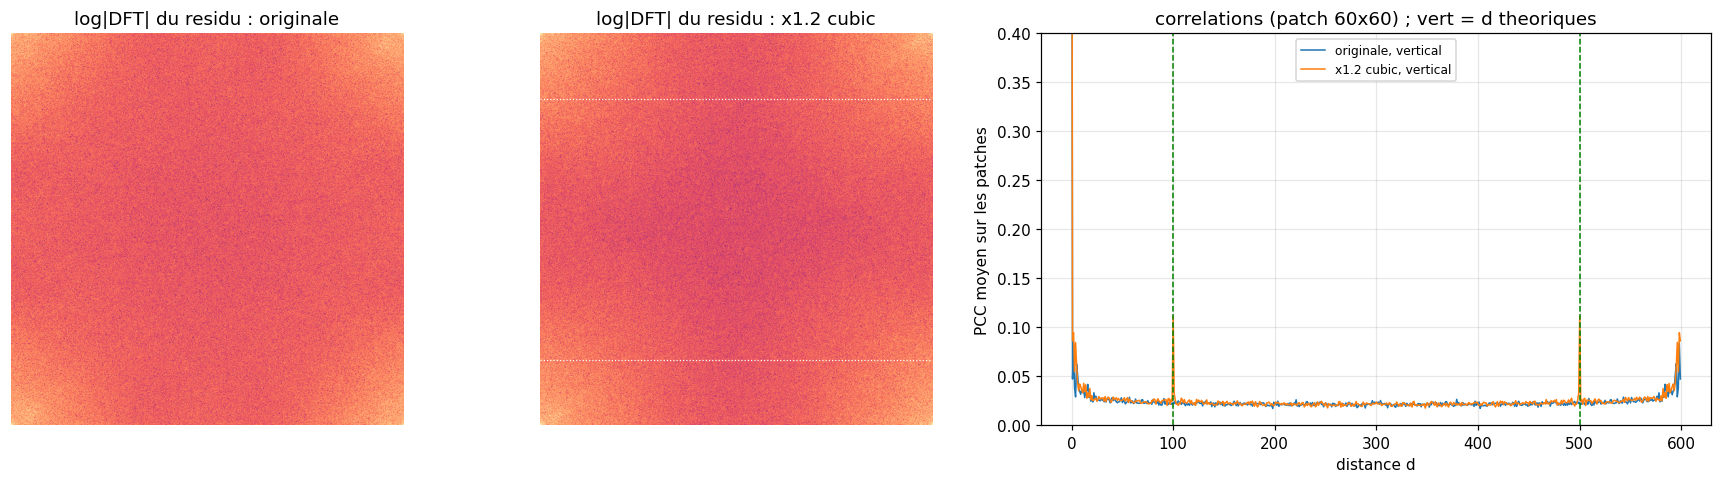

In [7]:
corr = {}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.5]})
for a, (k, R) in zip(ax[:2], Rs.items()):
    F = np.fft.fft2(R - R.mean())
    a.imshow(np.log1p(np.abs(F)), cmap="magma"); a.set_title(f"log|DFT| du residu : {k}"); a.axis("off")
    corr[k] = patch_correlations_2d(F, patch_ratio=10)
for d in d_exp:
    ax[1].axhline(d, color="w", ls=":", lw=0.8)
for k, (rv, rh, sh) in corr.items():
    ax[2].plot(rv.mean(0), lw=1, label=f"{k}, vertical")
for d in d_exp:
    ax[2].axvline(d, color="g", ls="--", lw=1)
ax[2].set_ylim(0, 0.4); ax[2].set_xlabel("distance d"); ax[2].set_ylabel("PCC moyen sur les patches")
ax[2].set_title(f"correlations (patch {sh[0]}x{sh[1]}) ; vert = d theoriques"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Votes, NFA, validation croisée et décision

- **Votes** $k(d)$ : nombre de patches dont la corrélation est maximale en $d$ sur $[\![d-r, d+r]\!]$ ($r = 20$). Sous $H_0$, $k(d) \sim \mathcal{B}(\#\mathcal{P}, \frac{1}{2r+1})$.
- **NFA** $= \#\mathcal{C} \cdot \mathcal{B}(k(d), \#\mathcal{P}, \frac{1}{2r+1})$ : nombre de fausses alarmes attendu ; une distance est validée si NFA $< \varepsilon = 1$.
- **Validation croisée** (éq. 23) : une distance verticale n'est gardée que si une distance proportionnelle est aussi significative horizontalement ($\beta = 0{,}005$).

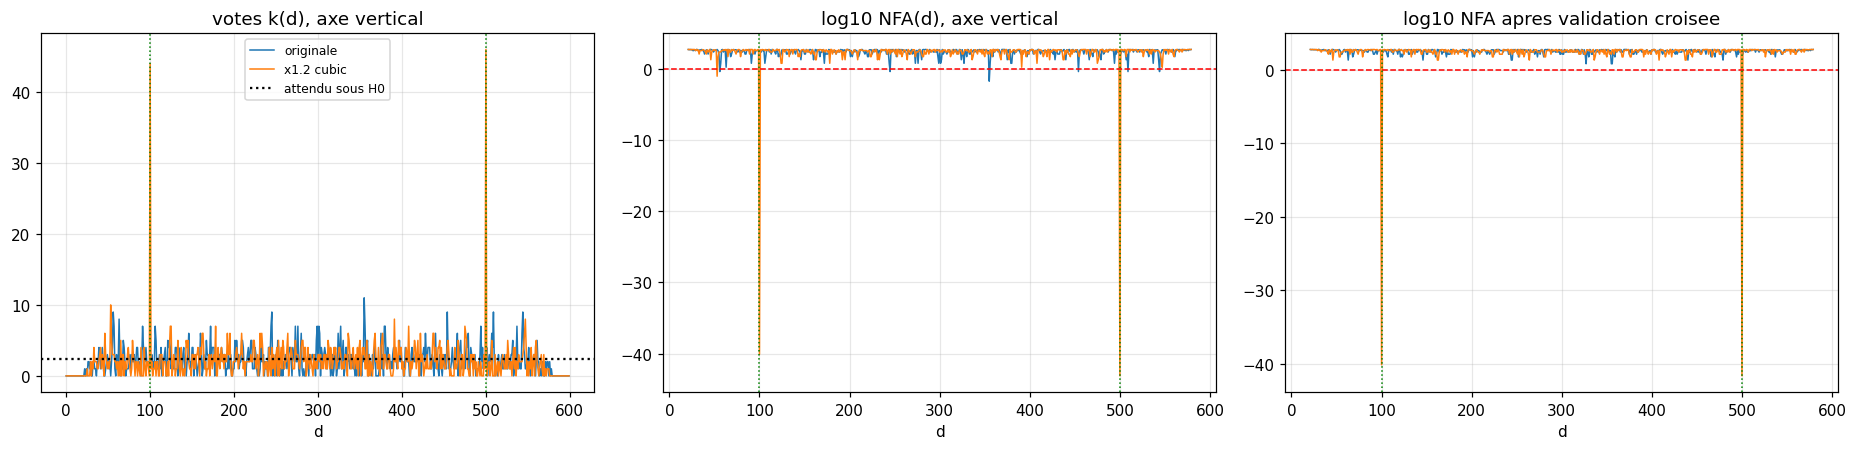

In [8]:
r = 20
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for k, (rv, rh, sh) in corr.items():
    kv = count_votes(rv, r)
    nv, nh = compute_nfa(rv, r), compute_nfa(rh, r)
    ncv = cross_validate(nv, nh, OUT_SIZE, OUT_SIZE, 0.005)
    with np.errstate(divide="ignore"):
        ax[0].plot(kv, lw=1, label=k)
        ax[1].plot(np.log10(nv), lw=1, label=k)
        ax[2].plot(np.log10(ncv), lw=1, label=k)
ax[0].axhline(rv.shape[0] / (2*r + 1), color="k", ls=":", label="attendu sous H0")
ax[0].set_title("votes k(d), axe vertical"); ax[0].legend(fontsize=8)
ax[1].set_title("log10 NFA(d), axe vertical"); ax[2].set_title("log10 NFA apres validation croisee")
for a in ax[1:]:
    a.axhline(0, color="r", ls="--", lw=1)
for a in ax:
    a.set_xlabel("d")
    for d in d_exp: a.axvline(d, color="g", ls=":", lw=1)
plt.tight_layout(); plt.show()

In [9]:
rows = []
for k, v in imgs.items():
    o = detect(v)
    rows.append({"image": k, "detecte": o["detected"], "d valides (V)": list(map(int, o["d_v"])),
                 "d valides (H)": list(map(int, o["d_h"])), "log10 NFA min": round(o["log10_nfa"], 1)})
display(pd.DataFrame(rows))
print("distances attendues pour l'image reechantillonnee :", [round(d, 1) for d in d_exp])

,image,detecte,d valides (V),d valides (H),log10 NFA min
0,originale,False,[],[],0.8
1,x1.2 cubic,True,"[100, 500]","[100, 500]",-41.6


distances attendues pour l'image reechantillonnee : [100.0, 500.0]


## 6. Étude statistique des résultats

Résultats de `scripts/run_detection.py` sur toutes les images PNG de la dataset. Pour chaque taux, on donne un **intervalle de confiance à 95 % de Clopper–Pearson** (exact pour une proportion binomiale) : avec peu de photos, un taux seul ne veut rien dire sans son incertitude.

In [10]:
res_df = pd.read_csv(RESULTS)
res_df = res_df[res_df["detected"].astype(str) != "ERROR"].copy()
res_df["detected"] = res_df["detected"].astype(str) == "True"
res_df["correct_d"] = res_df["correct_d"].astype(str) == "True"
res_df = res_df.merge(idx[["path", "device"]], on="path", how="left")
n_photos = res_df["id"].nunique()
print(f"{len(res_df)} images analysees, {n_photos} photos, format(s) : {res_df['format'].unique()}")

def ci(k, n, a=0.05):
    lo = beta.ppf(a/2, k, n-k+1) if k > 0 else 0.0
    hi = beta.ppf(1-a/2, k+1, n-k) if k < n else 1.0
    return 100*lo, 100*hi

820 images analysees, 20 photos, format(s) : ['png']


### 6.1 Faux positifs sur les originales

In [11]:
o = res_df[res_df["label"] == "original"]
k, n = int(o["detected"].sum()), len(o)
lo, hi = ci(k, n)
print(f"faux positifs : {k}/{n} = {100*k/n:.1f} %   IC95 = [{lo:.1f} ; {hi:.1f}] %")
if k: display(o[o["detected"]][["id", "d_v", "d_h", "log10_nfa"]])

faux positifs : 0/20 = 0.0 %   IC95 = [0.0 ; 16.8] %


### 6.2 Taux de détection par noyau et par facteur

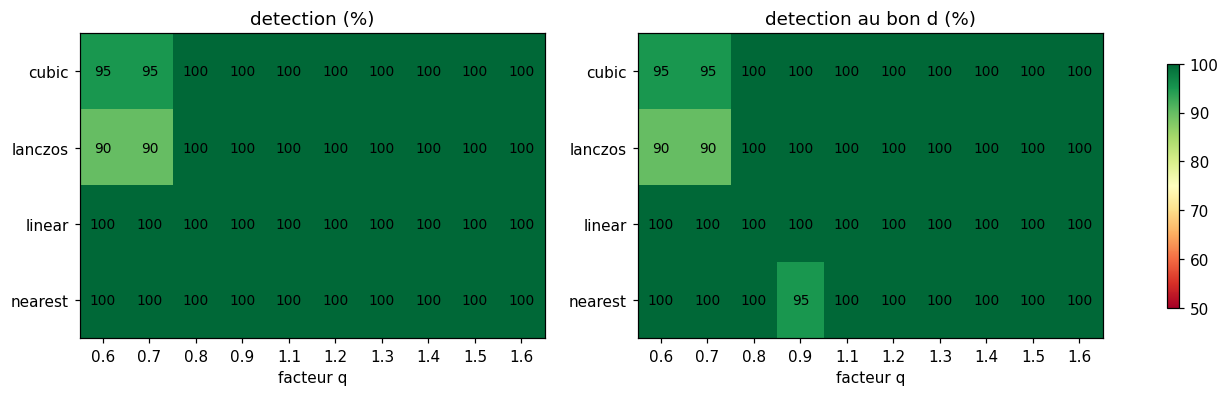

In [12]:
rs = res_df[res_df["label"] == "resampled"]
tab = rs.groupby(["kernel", "q"])["detected"].mean().unstack() * 100
tab_d = rs.groupby(["kernel", "q"])["correct_d"].mean().unstack() * 100
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
for a, t, title in [(ax[0], tab, "detection (%)"), (ax[1], tab_d, "detection au bon d (%)")]:
    im = a.imshow(t.values, cmap="RdYlGn", vmin=50, vmax=100, aspect="auto")
    a.set_xticks(range(t.shape[1])); a.set_xticklabels(t.columns); a.set_yticks(range(t.shape[0])); a.set_yticklabels(t.index)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            a.text(j, i, f"{t.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
    a.set_xlabel("facteur q"); a.set_title(title); a.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

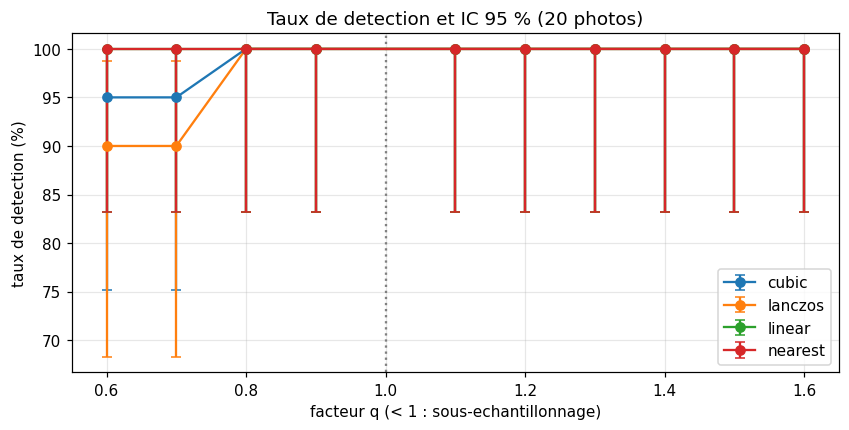

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
for kname, g in rs.groupby("kernel"):
    s = g.groupby("q")["detected"].agg(["sum", "count"])
    rate = 100 * s["sum"] / s["count"]
    lo, hi = zip(*[ci(int(a), int(b)) for a, b in zip(s["sum"], s["count"])])
    ax.errorbar(s.index, rate, yerr=[rate - np.array(lo), np.array(hi) - rate], marker="o", capsize=3, label=kname)
ax.axvline(1, color="gray", ls=":")
ax.set_xlabel("facteur q (< 1 : sous-echantillonnage)"); ax.set_ylabel("taux de detection (%)")
ax.set_title(f"Taux de detection et IC 95 % ({n_photos} photos)"); ax.legend(); plt.show()

### 6.3 Détections au mauvais endroit

In [14]:
bad = rs[rs["detected"] & ~rs["correct_d"]]
print(f"{len(bad)} detection(s) hors des distances attendues (tolerance +-1)")
display(bad[["id", "kernel", "q", "d1", "d2", "d_v", "d_h", "log10_nfa"]])

1 detection(s) hors des distances attendues (tolerance +-1)


,id,kernel,q,d1,d2,d_v,d_h,log10_nfa
291,r006b0e4bt,nearest,0.9,66.67,533.33,133 200 267 400 467,133 200 267 400 467,-4.04


### 6.4 Force des détections : distribution du log₁₀ NFA

Plus le log₁₀ NFA est négatif, plus la détection est sûre. Le seuil $\varepsilon = 1$ correspond à 0.

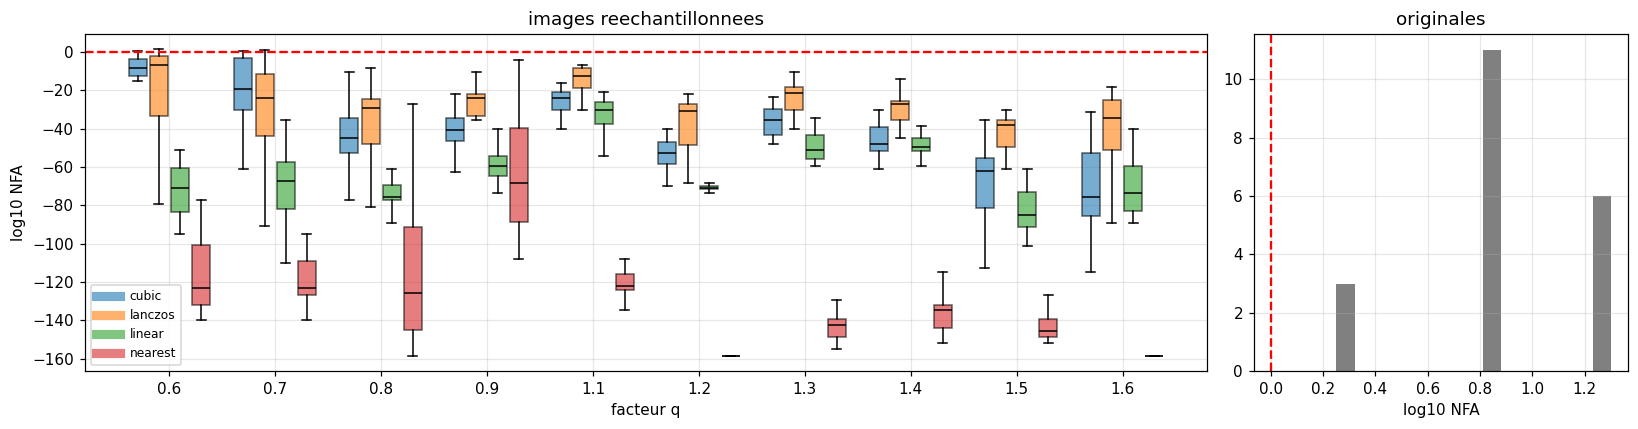

q,0.6,0.7,0.8,0.9,1.1,1.2,1.3,1.4,1.5,1.6
log10 NFA median,-55.1,-57.6,-67.2,-46.2,-30.0,-69.0,-43.1,-49.4,-75.4,-78.2


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [3, 1]})
qs = sorted(rs["q"].unique())
for i, kname in enumerate(sorted(rs["kernel"].unique())):
    g = rs[rs["kernel"] == kname]
    data = [g[g["q"] == q]["log10_nfa"].clip(lower=-200).values for q in qs]
    ax[0].boxplot(data, positions=np.arange(len(qs)) + (i - 1.5) * 0.2, widths=0.17, patch_artist=True,
                  boxprops=dict(facecolor=f"C{i}", alpha=0.6), medianprops=dict(color="k"), showfliers=False)
    ax[0].plot([], [], color=f"C{i}", lw=6, alpha=0.6, label=kname)
ax[0].set_xticks(range(len(qs))); ax[0].set_xticklabels(qs); ax[0].axhline(0, color="r", ls="--")
ax[0].set_xlabel("facteur q"); ax[0].set_ylabel("log10 NFA"); ax[0].legend(fontsize=8); ax[0].set_title("images reechantillonnees")
ax[1].hist(o["log10_nfa"], bins=15, color="gray"); ax[1].axvline(0, color="r", ls="--")
ax[1].set_xlabel("log10 NFA"); ax[1].set_title("originales")
plt.tight_layout(); plt.show()
display(rs.groupby("q")["log10_nfa"].median().round(1).to_frame("log10 NFA median").T)